# Predicting customer bookings

British Airways Data Science Job Simulation (Forage), Task 2. February 2026.

50,000 booking enquiries, each with the customer's choices (route, lead time, length of stay, add-ons) and whether the booking was completed. Only 15% of enquiries convert, so the target is imbalanced. The aim is to predict which customers will book and, more usefully, to show which variables drive that outcome.

**Outline**
1. Explore and prepare the dataset
2. Random forest baseline with cross-validation
3. Diagnosis: why high accuracy hides a weak model
4. Second iteration: fewer features, regularised trees
5. Findings

The data file is provided by Forage for simulation use only and is not included in this repository.

## 1. Explore and prepare the dataset

In [1]:
# Explore and prepare the dataset

import pandas as pd
import numpy as np

# Optional: nicer displays
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

# ----------------
# 1) Load dataset
# ----------------
df = pd.read_csv("data/customer_booking.csv", encoding='latin-1')
print("Shape:", df.shape)
display(df.head())

# ----------------------------
# 2) Quick overview & checks
# ----------------------------
print("\n--- Info ---")
df.info()

print("\n--- Missing values (count) ---")
missing_counts = df.isna().sum().sort_values(ascending=False)
print(missing_counts[missing_counts > 0])

print("\n--- Target distribution (booking_complete) ---")
if "booking_complete" in df.columns:
    print(df["booking_complete"].value_counts(dropna=False))
    print(df["booking_complete"].value_counts(normalize=True, dropna=False).round(4))

print("\n--- Duplicate rows ---")
print("Duplicates:", df.duplicated().sum())

# ------------------------------------------
# 3) Basic EDA: numeric & categorical summary
# ------------------------------------------
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("\nNumeric columns:", num_cols)
print("Categorical columns:", cat_cols)

print("\n--- Numeric describe ---")
display(df[num_cols].describe().T)

print("\n--- Top values per categorical column ---")
for c in cat_cols:
    print(f"\n{c} (unique={df[c].nunique(dropna=True)})")
    display(df[c].value_counts(dropna=False).head(10))

# ---------------------------------------------------
# 4) Minimal cleaning: fix types + handle duplicates
# ---------------------------------------------------
# Drop exact duplicates (safe)
df = df.drop_duplicates().reset_index(drop=True)

# If there are date columns stored as strings, convert them
# (Uncomment/adjust if your dataset has date-like columns)
# for col in ["flight_date", "booking_date"]:
#     if col in df.columns:
#         df[col] = pd.to_datetime(df[col], errors="coerce")

# -----------------------------------------
# 5) Feature engineering (generic & safe)
# -----------------------------------------
df_fe = df.copy()

# Example: create interaction-style features if present
# (These are common in airline booking datasets, but guarded with if-checks)

if "flight_duration" in df_fe.columns and "length_of_stay" in df_fe.columns:
    df_fe["duration_x_stay"] = df_fe["flight_duration"] * df_fe["length_of_stay"]

if "wants_extra_baggage" in df_fe.columns and "wants_preferred_seat" in df_fe.columns:
    df_fe["wants_both_baggage_and_seat"] = (
        (df_fe["wants_extra_baggage"] == 1) & (df_fe["wants_preferred_seat"] == 1)
    ).astype(int)

# Optional: cap extreme outliers for numeric columns (simple winsorization)
# Uncomment if needed
# for c in num_cols:
#     lo, hi = df_fe[c].quantile([0.01, 0.99])
#     df_fe[c] = df_fe[c].clip(lo, hi)

# -------------------------------------------------------
# 6) Prepare X / y and preprocessing pipeline components
# -------------------------------------------------------
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

TARGET = "booking_complete"  # change if your target column name differs

if TARGET not in df_fe.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Columns are: {df_fe.columns.tolist()}")

X = df_fe.drop(columns=[TARGET])
y = df_fe[TARGET].astype(int)

# Recompute column lists after feature engineering
num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("\nPrepared features:")
print("Numeric:", num_features)
print("Categorical:", cat_features)
print("X shape:", X.shape, "| y shape:", y.shape)

# Numeric preprocessing: median impute
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing: most_frequent impute + one-hot
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_features),
        ("cat", categorical_transformer, cat_features),
    ],
    remainder="drop"
)

# -----------------------------------
# 7) Train/test split (for later tasks)
# -----------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

# ---------------------------------------------
# 8) Fit preprocessor and output prepared arrays
# ---------------------------------------------
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("\nPrepared matrices:")
print("X_train_prepared:", X_train_prepared.shape)
print("X_test_prepared :", X_test_prepared.shape)

# Get final feature names (useful for later feature importance)
ohe = preprocessor.named_transformers_["cat"].named_steps["onehot"]
cat_ohe_names = ohe.get_feature_names_out(cat_features) if len(cat_features) else np.array([])

feature_names = np.concatenate([np.array(num_features), cat_ohe_names])

print("\nTotal final features:", len(feature_names))
print("First 25 feature names:", feature_names[:25])


Shape: (50000, 14)


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0



--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  str    
 2   trip_type              50000 non-null  str    
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  str    
 7   route                  50000 non-null  str    
 8   booking_origin         50000 non-null  str    
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), str(5)
memory usage: 5.3 M

,count,mean,std,min,25%,50%,75%,max
num_passengers,50000.0,1.591240,1.020165,1.00,1.00,1.00,2.00,9.0
purchase_lead,50000.0,84.940480,90.451378,0.00,21.00,51.00,115.00,867.0
length_of_stay,50000.0,23.044560,33.887670,0.00,5.00,17.00,28.00,778.0
flight_hour,50000.0,9.066340,5.412660,0.00,5.00,9.00,13.00,23.0
wants_extra_baggage,50000.0,0.668780,0.470657,0.00,0.00,1.00,1.00,1.0
wants_preferred_seat,50000.0,0.296960,0.456923,0.00,0.00,0.00,1.00,1.0
wants_in_flight_meals,50000.0,0.427140,0.494668,0.00,0.00,0.00,1.00,1.0
flight_duration,50000.0,7.277561,1.496863,4.67,5.62,7.57,8.83,9.5
booking_complete,50000.0,0.149560,0.356643,0.00,0.00,0.00,0.00,1.0



--- Top values per categorical column ---

sales_channel (unique=2)


sales_channel
Internet    44382
Mobile       5618
Name: count, dtype: int64

... (6 outputs left out)


booking_origin (unique=104)


booking_origin
Australia      17872
Malaysia        7174
South Korea     4559
Japan           3885
China           3387
Indonesia       2369
Taiwan          2077
Thailand        2030
India           1270
New Zealand     1074
Name: count, dtype: int64


Prepared features:
Numeric: ['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration', 'duration_x_stay', 'wants_both_baggage_and_seat']
Categorical: ['sales_channel', 'trip_type', 'flight_day', 'route', 'booking_origin']
X shape: (49281, 15) | y shape: (49281,)
Train: (39424, 15) Test: (9857, 15)



Prepared matrices:
X_train_prepared: (39424, 903)
X_test_prepared : (9857, 903)

Total final features: 903
First 25 feature names: ['num_passengers' 'purchase_lead' 'length_of_stay' 'flight_hour'
 'wants_extra_baggage' 'wants_preferred_seat' 'wants_in_flight_meals'
 'flight_duration' 'duration_x_stay' 'wants_both_baggage_and_seat'
 'sales_channel_Internet' 'sales_channel_Mobile' 'trip_type_CircleTrip'
 'trip_type_OneWay' 'trip_type_RoundTrip' 'flight_day_Fri'
 'flight_day_Mon' 'flight_day_Sat' 'flight_day_Sun' 'flight_day_Thu'
 'flight_day_Tue' 'flight_day_Wed' 'route_AKLDEL' 'route_AKLHGH'
 'route_AKLHND']


## 2. Random forest baseline

A random forest handles mixed feature types without scaling, copes with the non-linear effect of lead time, and reports feature importances directly. The baseline uses every column, one-hot encoded, and five-fold stratified cross-validation on the training split before a final hold-out evaluation.

Numeric features: ['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration']
Categorical features: ['sales_channel', 'trip_type', 'flight_day', 'route', 'booking_origin']



--- Cross-validation (train split only) ---
accuracy : mean=0.8233  std=0.0011
precision: mean=0.4033  std=0.0030
recall   : mean=0.3719  std=0.0113
f1       : mean=0.3869  std=0.0067
roc_auc  : mean=0.7828  std=0.0021



--- Test set performance ---
Accuracy : 0.8214
Precision: 0.3989
Recall   : 0.3762
F1       : 0.3872
ROC-AUC  : 0.7748

Confusion matrix:
[[7541  838]
 [ 922  556]]

Classification report:
              precision    recall  f1-score   support

           0     0.8911    0.9000    0.8955      8379
           1     0.3989    0.3762    0.3872      1478

    accuracy                         0.8214      9857
   macro avg     0.6450    0.6381    0.6413      9857
weighted avg     0.8173    0.8214    0.8193      9857



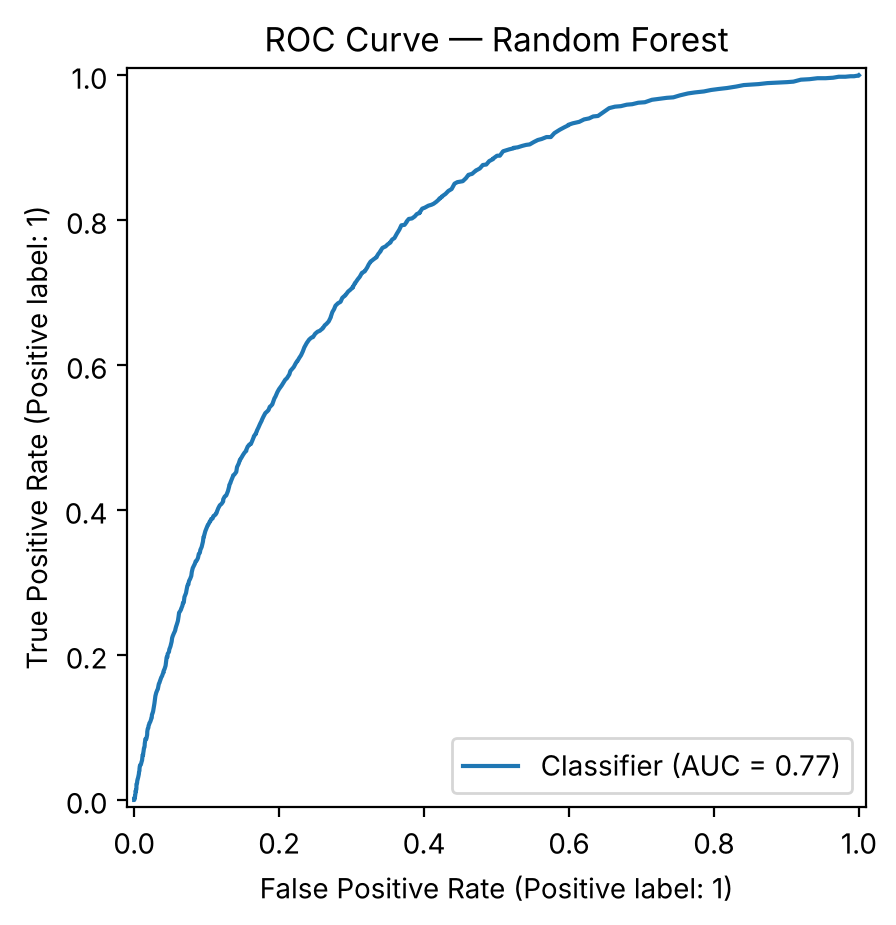


Top 25 features by importance:


,feature,importance
0,purchase_lead,0.122222
1,length_of_stay,0.102115
2,flight_hour,0.100447
3,booking_origin_Australia,0.052731
4,flight_duration,0.042627
5,num_passengers,0.039526
6,booking_origin_Malaysia,0.036380
7,wants_in_flight_meals,0.019082
8,wants_extra_baggage,0.017068
9,wants_preferred_seat,0.015778


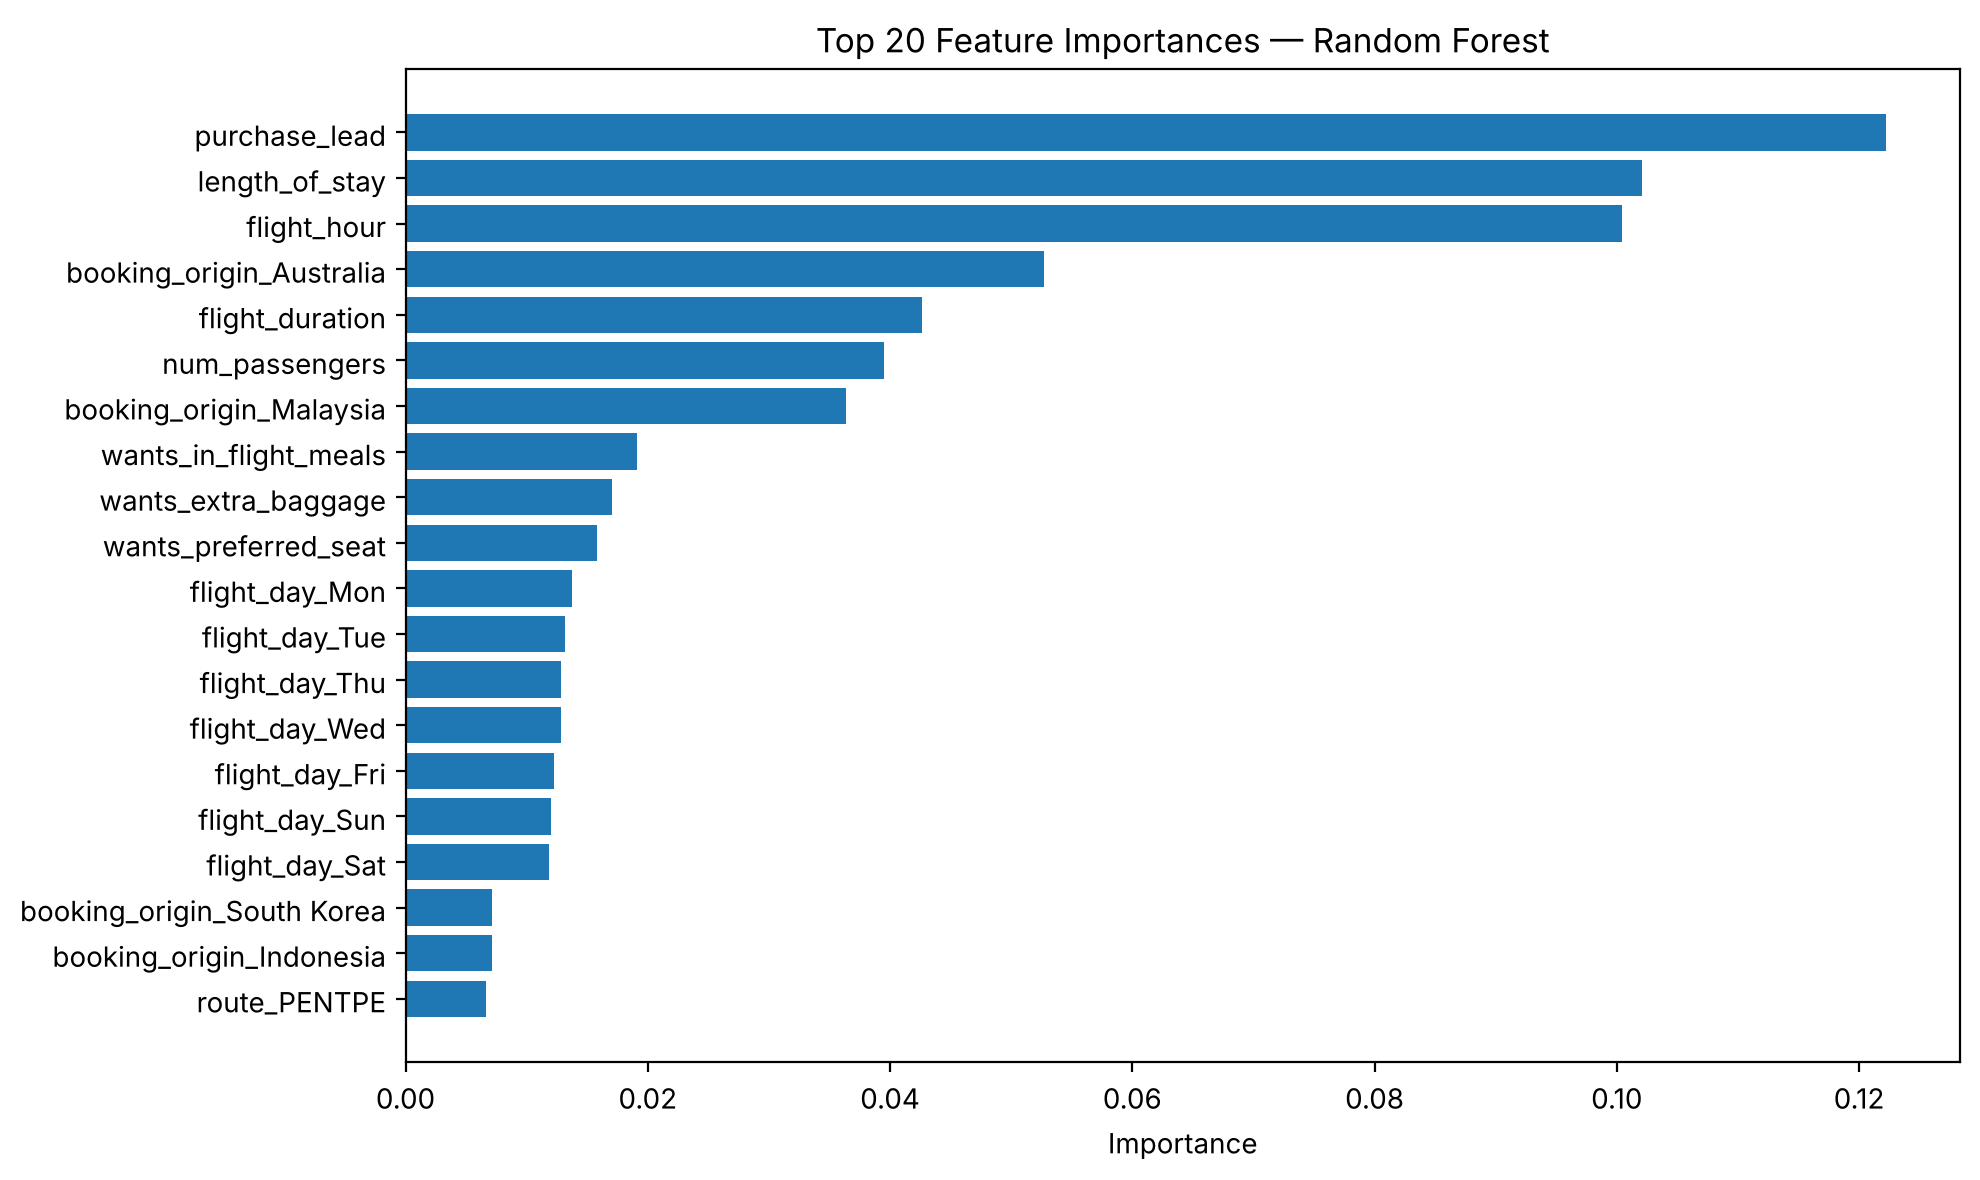

In [2]:
#   ================================
# Task 2 — Train a model (Random Forest) + evaluate
# For Google Colab
# ================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)
from sklearn.ensemble import RandomForestClassifier

import matplotlib.pyplot as plt

# ----------------
# 1) Load dataset
# ----------------
df = pd.read_csv("data/customer_booking.csv", encoding='latin-1')
df = df.drop_duplicates().reset_index(drop=True)

TARGET = "booking_complete"  # change if your target differs
if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Columns: {df.columns.tolist()}")

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

# -----------------------------
# 2) Identify feature types
# -----------------------------
num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numeric features:", num_features)
print("Categorical features:", cat_features)

# -----------------------------------------
# 3) Preprocessing (impute + one-hot)
# -----------------------------------------
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_features),
        ("cat", categorical_transformer, cat_features),
    ],
    remainder="drop",
)

# -----------------------------------------
# 4) Model (tweakable parameters)
# -----------------------------------------
rf = RandomForestClassifier(
    n_estimators=400,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced",   # helps if classes are imbalanced
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1
)

model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("rf", rf)
])

# -----------------------------
# 5) Train/test split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# -----------------------------
# 6) Cross-validation (CV)
# -----------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = cross_validate(
    model,
    X_train, y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

print("\n--- Cross-validation (train split only) ---")
for metric in scoring.keys():
    scores = cv_results[f"test_{metric}"]
    print(f"{metric:9s}: mean={scores.mean():.4f}  std={scores.std():.4f}")

# -----------------------------
# 7) Fit on full train split
# -----------------------------
model.fit(X_train, y_train)

# -----------------------------
# 8) Evaluate on held-out test split
# -----------------------------
y_pred = model.predict(X_test)

# Some models expose predict_proba; RF does
y_proba = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_proba)

print("\n--- Test set performance ---")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1       : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=4))

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC Curve — Random Forest")
plt.show()

# -----------------------------------------
# 9) Feature importance (interpretable output)
# -----------------------------------------
# Get feature names after preprocessing
pre = model.named_steps["preprocess"]
rf_fitted = model.named_steps["rf"]

# numeric names
num_names = np.array(num_features)

# one-hot names
if len(cat_features) > 0:
    ohe = pre.named_transformers_["cat"].named_steps["onehot"]
    cat_names = ohe.get_feature_names_out(cat_features)
else:
    cat_names = np.array([])

feature_names = np.concatenate([num_names, cat_names])

importances = rf_fitted.feature_importances_
fi = pd.DataFrame({"feature": feature_names, "importance": importances})
fi = fi.sort_values("importance", ascending=False).reset_index(drop=True)

print("\nTop 25 features by importance:")
display(fi.head(25))

# Optional: plot top 20 (no custom colors)
top_n = 20
plt.figure(figsize=(10, 6))
plt.barh(fi.loc[:top_n-1, "feature"][::-1], fi.loc[:top_n-1, "importance"][::-1])
plt.title(f"Top {top_n} Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 3. Diagnosis

Accuracy of 0.82 to 0.85 looks respectable until you notice that 85% of enquiries do not convert, so predicting "no booking" for everyone would score the same. The confusion matrix shows what is really happening: the model recovers only a minority of eventual bookers (recall 0.10 in the original Colab run; 0.37 on a rerun with a newer scikit-learn version, which breaks ties differently in trees with this many columns), while ROC-AUC of 0.78 says the ranking of probabilities is reasonably good.

The cause is overfitting. `route` has 799 values, so one-hot encoding produces about 900 columns, and with `max_depth=None` each tree grows until it has memorised the training rows. The forest then becomes confident and conservative on new data. Lead time, length of stay and flight hour still come out as the top drivers, which is consistent with the shape of the data.

## 4. Second iteration

Three changes, each with a reason:
- Drop `route`: the information it carries (duration, origin market) is already present in `flight_duration` and `booking_origin`, and it dominates the feature space.
- Group booking origins with fewer than 500 enquiries as `Other`, so the model is not learning from a handful of rows per country.
- Regularise the trees (`max_depth=12`, `min_samples_leaf=20`) so that `class_weight="balanced"` can do its job of lifting the minority class instead of being overridden by memorised leaves.

Features after encoding: 28



--- Cross-validation, second iteration ---
accuracy : mean=0.6994  std=0.0030
precision: mean=0.2894  std=0.0027
recall   : mean=0.6899  std=0.0016
f1       : mean=0.4078  std=0.0029
roc_auc  : mean=0.7600  std=0.0029



--- Test set, second iteration ---
Recall   : 0.6996
Precision: 0.2892
ROC-AUC  : 0.7574

Confusion matrix:
[[5838 2541]
 [ 444 1034]]


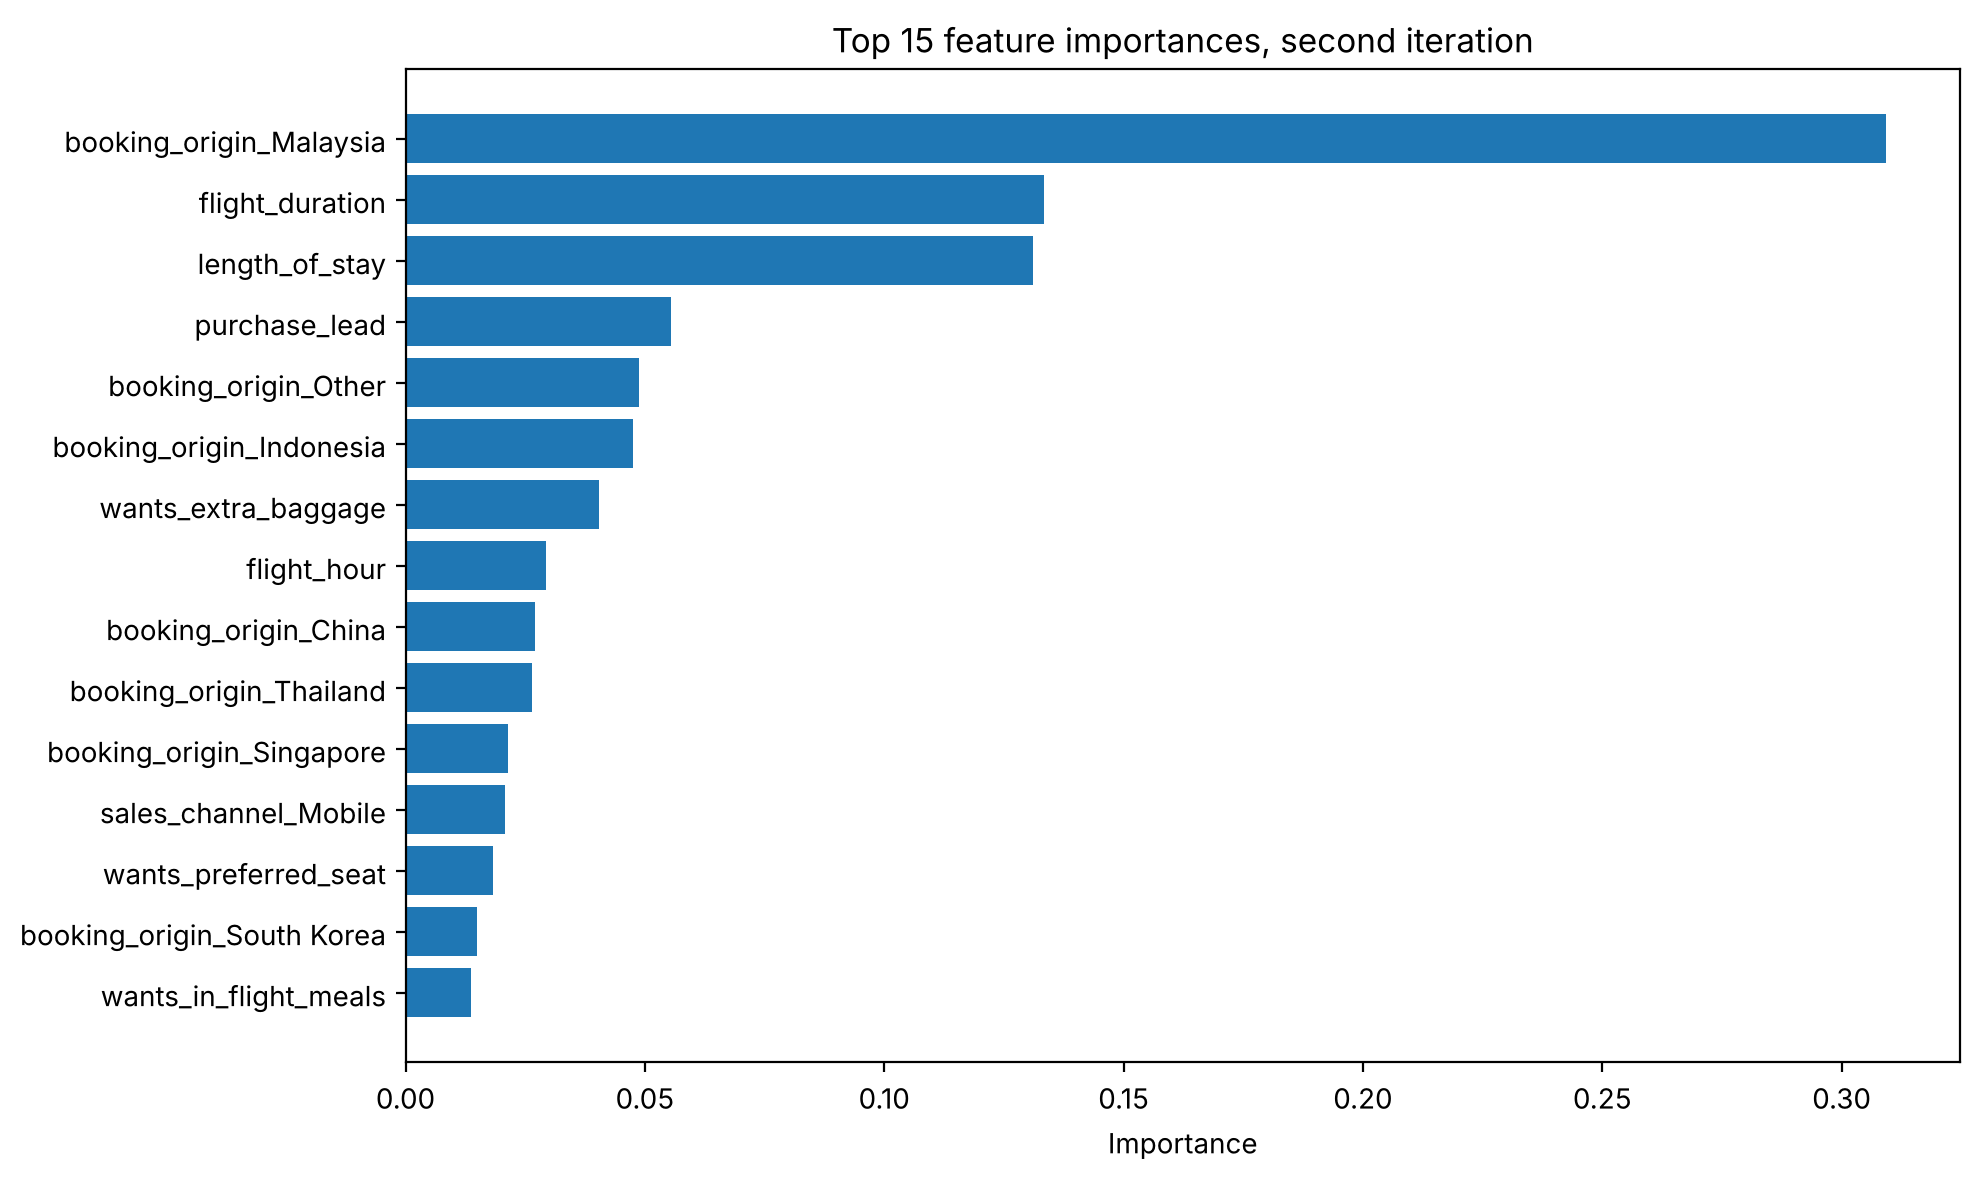

booking_origin_Malaysia       0.309
flight_duration               0.133
length_of_stay                0.131
purchase_lead                 0.055
booking_origin_Other          0.049
booking_origin_Indonesia      0.047
wants_extra_baggage           0.040
flight_hour                   0.029
booking_origin_China          0.027
booking_origin_Thailand       0.026
booking_origin_Singapore      0.021
sales_channel_Mobile          0.021
wants_preferred_seat          0.018
booking_origin_South Korea    0.015
wants_in_flight_meals         0.014
dtype: float64

In [3]:
df2 = df.drop(columns=["route"]).copy()
counts = df2["booking_origin"].value_counts()
df2["booking_origin"] = df2["booking_origin"].where(df2["booking_origin"].map(counts) >= 500, "Other")

X2 = pd.get_dummies(df2.drop(columns=[TARGET]), drop_first=True)
y2 = df2[TARGET].astype(int)
print("Features after encoding:", X2.shape[1])

rf2 = RandomForestClassifier(
    n_estimators=300, max_depth=12, min_samples_leaf=20,
    class_weight="balanced", random_state=42, n_jobs=-1)

cv_results2 = cross_validate(rf2, X2, y2, cv=cv, scoring=scoring, n_jobs=-1)
print("\n--- Cross-validation, second iteration ---")
for metric in scoring:
    s = cv_results2[f"test_{metric}"]
    print(f"{metric:9s}: mean={s.mean():.4f}  std={s.std():.4f}")

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)
rf2.fit(X2_train, y2_train)
y2_pred = rf2.predict(X2_test)
y2_proba = rf2.predict_proba(X2_test)[:, 1]
print("\n--- Test set, second iteration ---")
print(f"Recall   : {recall_score(y2_test, y2_pred):.4f}")
print(f"Precision: {precision_score(y2_test, y2_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y2_test, y2_proba):.4f}")
print("\nConfusion matrix:")
print(confusion_matrix(y2_test, y2_pred))

fi2 = pd.Series(rf2.feature_importances_, index=X2.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
plt.barh(fi2.head(15).index[::-1], fi2.head(15).values[::-1])
plt.title("Top 15 feature importances, second iteration")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()
fi2.head(15).round(3)

## 5. Findings

- **Judged on the right metrics, the second model is far more useful.** Recall rises to about 0.70 at a similar ROC-AUC, at the cost of precision (about 0.29) and headline accuracy. For a marketing use case, such as choosing who receives a reminder or an offer, catching most eventual bookers is worth some wasted contacts; for revenue forecasting the trade-off would be set differently.
- **Lead time, length of stay and flight hour are the consistent drivers** in the baseline. Once `route` is removed, the origin market comes to the front: Malaysian enquiries convert at about 34% against 5% for Australia, which makes up a third of the data.
- **Add-ons carry moderate signal, channel and day of week very little.**

Next steps would be customer-level features (loyalty status, previous bookings), tuning the decision threshold to the real cost of a missed booking versus a wasted contact, and checking whether the Malaysia effect reflects the market or how the sample was collected.